# 🎓 Student Academic Performance — Multiclass KNN Classification
**Predicting Academic Achievement (`GradeClass`) from Study Habits and Demographic Factors**

This notebook develops an end-to-end multiclass classification model predicting student academic achievement tiers (`GradeClass`: 0=A, 1=B, 2=C, 3=D, 4=F) using behavioral, demographic, and educational engagement features.

### 📋 Key Workflow Stages:
1. **Data Ingestion & Verification**: Loading 2,392 student records.
2. **Data Cleaning & Leakage Prevention**: Removing uninformative identifiers (`StudentID`) and direct mathematical target derivations (`GPA`).
3. **Exploratory Data Analysis (EDA)**: Class imbalance audit and correlation matrix.
4. **Data Preprocessing**: Stratified train-test splitting and Z-Score standardization.
5. **K-Nearest Neighbors Multiclass Model**: Evaluating $K \in [1, 25]$ to optimize multiclass decision boundaries.
6. **Comprehensive Model Evaluation**: Multiclass confusion matrix, macro/weighted F1-score, and classification report.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Data Ingestion & Structural Inspection

In [2]:
df = pd.read_csv("Student_performance_data.csv")
print(f"Dataset loaded: {df.shape[0]:,} students x {df.shape[1]} features\n")
display(df.head())
print("\nDataset Info:")
df.info()


Dataset loaded: 2,392 students x 15 features



,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


## 2. Data Quality Audit & Leakage Prevention
- **Missing Values & Duplicates**: Audit data cleanliness.
- **Preventing Target Leakage**: `GPA` directly determines `GradeClass` via deterministic mathematical thresholds ($A \ge 3.5$, $B \ge 3.0$, etc.). Retaining `GPA` in the predictor set would constitute severe target leakage. We drop `StudentID` (arbitrary ID) and `GPA`.


In [3]:
print(f"Missing Values: {df.isna().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

# Drop ID and leakage variable
df_clean = df.drop(columns=['StudentID', 'GPA'])
print(f"\nCleaned Dataset Shape: {df_clean.shape}")


Missing Values: 0
Duplicate Rows: 0

Cleaned Dataset Shape: (2392, 13)


## 3. Target Distribution: Academic Grade Classes (`GradeClass`)
- **Class 0**: 'A' (Excellent)
- **Class 1**: 'B' (Above Average)
- **Class 2**: 'C' (Average)
- **Class 3**: 'D' (Below Average)
- **Class 4**: 'F' (Failing)


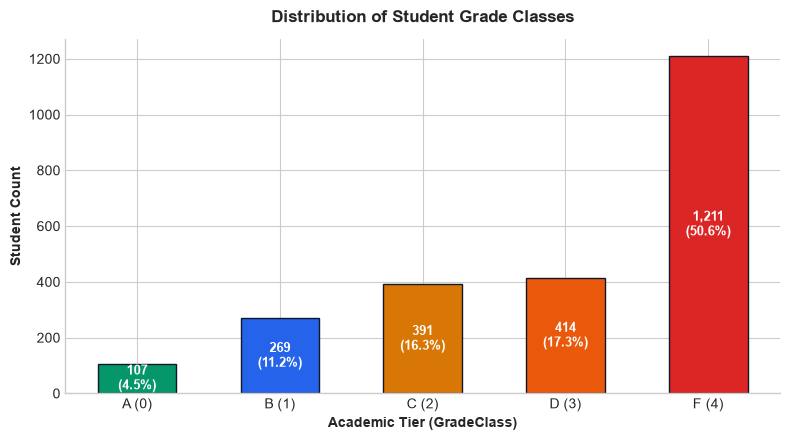

In [4]:
grade_labels = ['A (0)', 'B (1)', 'C (2)', 'D (3)', 'F (4)']
counts = df_clean['GradeClass'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
palette = ['#059669', '#2563EB', '#D97706', '#EA580C', '#DC2626']

bars = ax.bar(grade_labels, counts.values, color=palette, edgecolor='#0F172A', width=0.55)
ax.set_title("Distribution of Student Grade Classes", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Academic Tier (GradeClass)", fontweight='bold')
ax.set_ylabel("Student Count", fontweight='bold')

for b in bars:
    h = b.get_height()
    pct = (h / len(df_clean)) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(b.get_x() + b.get_width() / 2, h / 2),
                xytext=(0, 0), textcoords="offset points", ha='center', va='center',
                color='white', fontweight='bold', fontsize=9.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()


## 4. Key Predictor Visualizations & Correlation Heatmap

C:\Users\arjun\AppData\Local\Temp\ipykernel_7592\3221325287.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='GradeClass', y='StudyTimeWeekly', palette=palette, ax=axes[0])
C:\Users\arjun\AppData\Local\Temp\ipykernel_7592\3221325287.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(grade_labels)
C:\Users\arjun\AppData\Local\Temp\ipykernel_7592\3221325287.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='GradeClass', y='Absences', palette=palette, ax=axes[1])
C:\Users\arjun\AppData\Local\Temp\ipykernel_7592

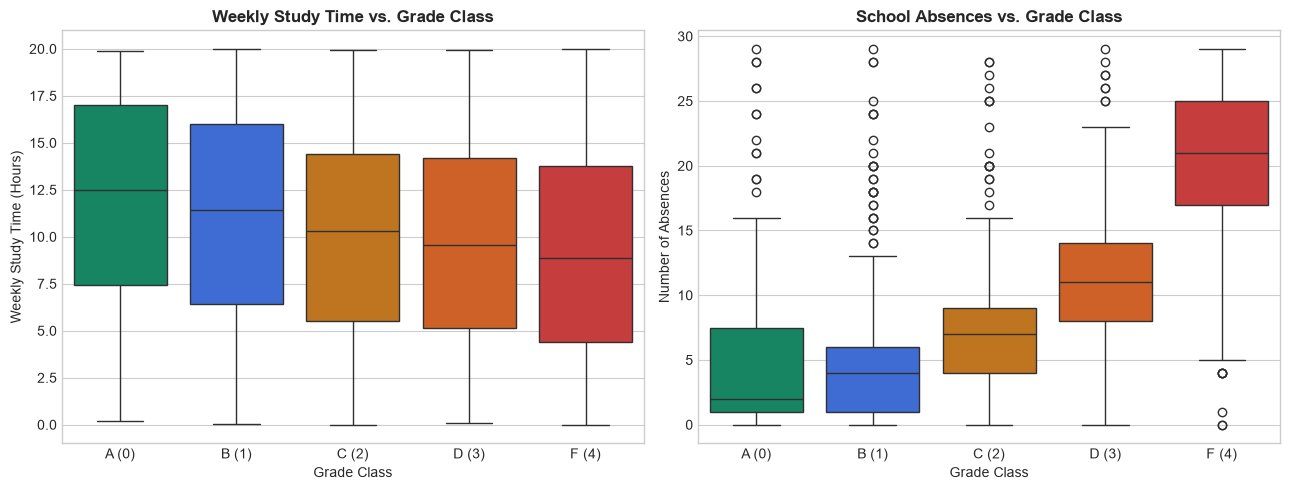

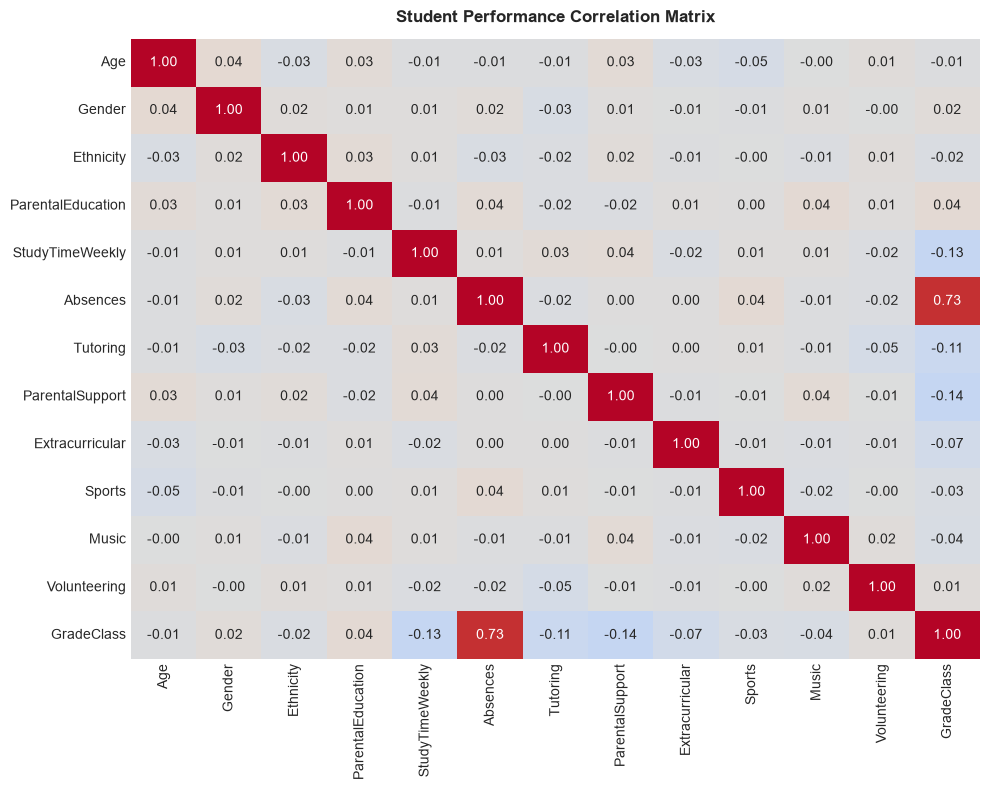

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)

# Study Time vs GradeClass
sns.boxplot(data=df_clean, x='GradeClass', y='StudyTimeWeekly', palette=palette, ax=axes[0])
axes[0].set_title("Weekly Study Time vs. Grade Class", fontweight='bold')
axes[0].set_xticklabels(grade_labels)
axes[0].set_xlabel("Grade Class")
axes[0].set_ylabel("Weekly Study Time (Hours)")

# Absences vs GradeClass
sns.boxplot(data=df_clean, x='GradeClass', y='Absences', palette=palette, ax=axes[1])
axes[1].set_title("School Absences vs. Grade Class", fontweight='bold')
axes[1].set_xticklabels(grade_labels)
axes[1].set_xlabel("Grade Class")
axes[1].set_ylabel("Number of Absences")

plt.tight_layout()
plt.show()

# Correlation Matrix
plt.figure(figsize=(10, 8), dpi=100)
sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.8, vmax=0.8, cbar=False)
plt.title("Student Performance Correlation Matrix", fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 5. Feature Formulation, Train-Test Partitioning & Scaling

In [6]:
X = df_clean.drop(columns=['GradeClass'])
y = df_clean['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")
print("Features standardized to mean=0, variance=1.")


X_train Shape: (1794, 12) | X_test Shape: (598, 12)
Features standardized to mean=0, variance=1.


## 6. KNN Multiclass Hyperparameter Tuning ($K \in [1, 25]$)

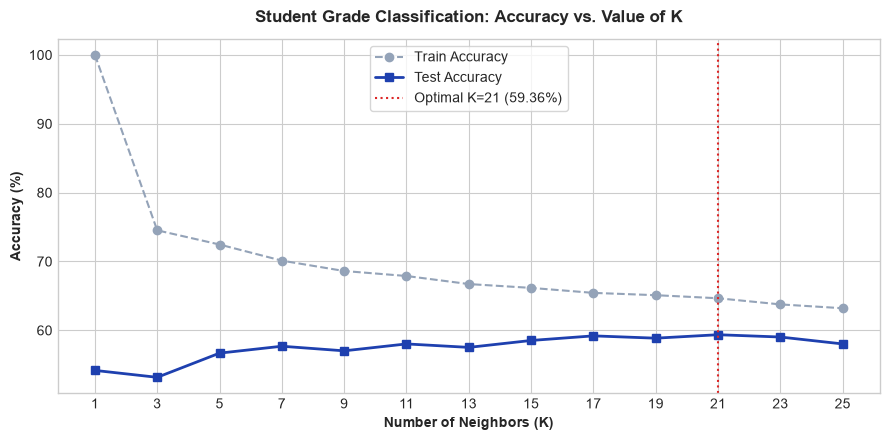

In [7]:
k_range = list(range(1, 27, 2))
train_accs = []
test_accs = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    train_accs.append(accuracy_score(y_train, knn.predict(X_train_scaled)))
    test_accs.append(accuracy_score(y_test, knn.predict(X_test_scaled)))

plt.figure(figsize=(9, 4.5), dpi=100)
plt.plot(k_range, [a * 100 for a in train_accs], 'o--', color='#94A3B8', label='Train Accuracy')
plt.plot(k_range, [a * 100 for a in test_accs], 's-', color='#1E40AF', label='Test Accuracy', lw=2)

best_k_idx = np.argmax(test_accs)
optimal_k = k_range[best_k_idx]
optimal_acc = test_accs[best_k_idx] * 100

plt.axvline(optimal_k, color='#DC2626', linestyle=':', label=f'Optimal K={optimal_k} ({optimal_acc:.2f}%)')
plt.title("Student Grade Classification: Accuracy vs. Value of K", fontweight='bold', fontsize=12, pad=12)
plt.xlabel("Number of Neighbors (K)", fontweight='bold')
plt.ylabel("Accuracy (%)", fontweight='bold')
plt.xticks(k_range)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Final Tuned Model
best_knn = KNeighborsClassifier(n_neighbors=optimal_k, metric='euclidean')
best_knn.fit(X_train_scaled, y_train)
y_pred = best_knn.predict(X_test_scaled)


## 7. Multiclass Model Evaluation & Diagnostic Insights

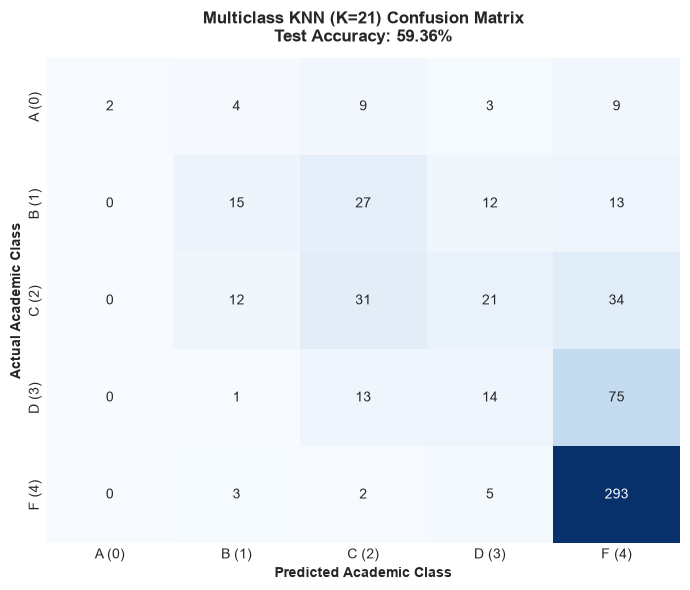

MULTICLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

       A (0)       1.00      0.07      0.14        27
       B (1)       0.43      0.22      0.29        67
       C (2)       0.38      0.32      0.34        98
       D (3)       0.25      0.14      0.18       103
       F (4)       0.69      0.97      0.81       303

    accuracy                           0.59       598
   macro avg       0.55      0.34      0.35       598
weighted avg       0.55      0.59      0.53       598



In [8]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=100)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=grade_labels, yticklabels=grade_labels, cbar=False)
ax.set_title(f"Multiclass KNN (K={optimal_k}) Confusion Matrix\nTest Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%", fontweight='bold', pad=12)
ax.set_xlabel("Predicted Academic Class", fontweight='bold')
ax.set_ylabel("Actual Academic Class", fontweight='bold')
plt.tight_layout()
plt.show()

print("=" * 65)
print("MULTICLASS CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_test, y_pred, target_names=grade_labels))
